In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go



In [25]:
df=pd.read_csv("https://raw.githubusercontent.com/awais-DS/Data/refs/heads/main/CarPrice_Assignment.csv",usecols=["wheelbase","enginesize","horsepower","price"])

In [26]:
df.head()

,wheelbase,enginesize,horsepower,price
0,88.6,130,111,13495.0
1,88.6,130,111,16500.0
2,94.5,152,154,16500.0
3,99.8,109,102,13950.0
4,99.4,136,115,17450.0


In [27]:
df.shape

(205, 4)

In [28]:
df.isnull().sum()

,0
wheelbase,0
enginesize,0
horsepower,0
price,0


In [29]:
df.dtypes

,0
wheelbase,float64
enginesize,int64
horsepower,int64
price,float64


In [30]:
df.columns

Index(['wheelbase', 'enginesize', 'horsepower', 'price'], dtype='object')

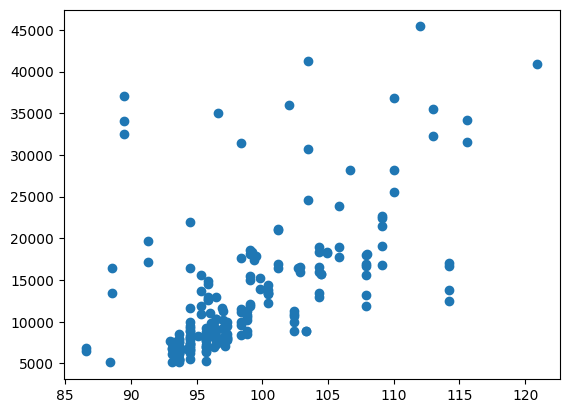

In [31]:
plt.scatter(df["wheelbase"],df["price"])

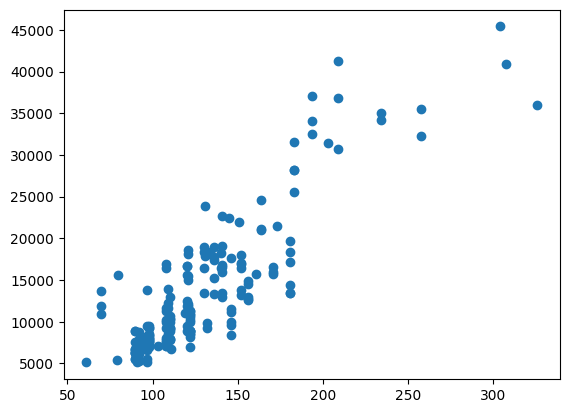

In [32]:
plt.scatter(df["enginesize"],df["price"])

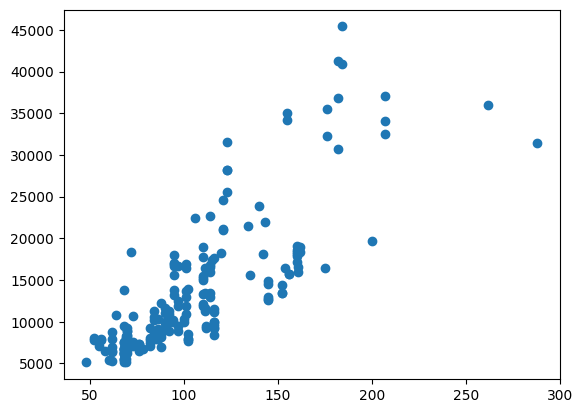

In [33]:
plt.scatter(df["horsepower"],df["price"])

In [38]:
import plotly.express as px
import plotly.io as pio


In [76]:
pio.renderers.default="iframe"
fig= px.scatter_3d(df,x="horsepower",y="wheelbase",z="price")
fig.show(renderer="vscode")

In [47]:
from sklearn.model_selection import train_test_split

In [55]:
x=df.iloc[:,0:3]
x.head()
x.shape

(205, 3)

In [60]:
y=df.iloc[:,-1]
y.head()
y.shape

(205,)

In [61]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=0)

In [64]:
from sklearn.linear_model import LinearRegression

In [65]:
lr=LinearRegression()

In [66]:
lr.fit(x_train,y_train)

LinearRegression()

In [71]:
y_pred=lr.predict(x_test)

In [69]:
y_test


,price
52,6795.0
181,15750.0
5,15250.0
18,5151.0
188,9995.0
170,11199.0
76,5389.0
154,7898.0
104,17199.0
33,6529.0


In [70]:
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

In [75]:
print("MAE",mean_absolute_error(y_test,y_pred))
print("MSE",mean_squared_error(y_test,y_pred))
print("R2Score",r2_score(y_test,y_pred))

MAE 2804.5170355388723
MSE 14278552.453313816
R2Score 0.8155615585489879


In [78]:
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

# 1. Generate the grid coordinates
x = np.linspace(-5, 5, 10)
y = np.linspace(-5, 5, 10)
xGrid, yGrid = np.meshgrid(y, x)

# FIX: Define 'final' FIRST so the model has data to predict on
final = np.vstack((xGrid.ravel().reshape(1,100), yGrid.ravel().reshape(1,100))).T

# 2. Get predictions from your trained model and reshape to a grid
z_final = lr.predict(final).reshape(10, 10)
z = z_final

# 3. Plot the real data points
fig = px.scatter_3d(df, x='horsepower', y='wheelbase', z='price')

# 4. Overlay the regression prediction surface
fig.add_trace(go.Surface(x=x, y=y, z=z, opacity=0.7, colorscale='Viridis'))

fig.show(renderer="vscode")


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning:

X does not have valid feature names, but LinearRegression was fitted with feature names



ValueError: X has 2 features, but LinearRegression is expecting 3 features as input.

In [79]:
# 1. Update the scatter plot with your specific features
fig = px.scatter_3d(
    df, 
    x='horsepower', 
    y='wheelbase', 
    z='price',
    labels={'horsepower': 'Horsepower (hp)', 'wheelbase': 'Wheelbase (in)', 'price': 'Price ($)'}
)

# 2. Add the regression surface
fig.add_trace(go.Surface(x=x, y=y, z=z, opacity=0.7, name="Regression Plane"))

fig.show()


NameError: name 'z' is not defined

In [80]:
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

# 1. Get exact min/max bounds from your dataset for the grid range
x_min, x_max = df['horsepower'].min(), df['horsepower'].max()
y_min, y_max = df['wheelbase'].min(), df['wheelbase'].max()

# 2. Generate the grid coordinates using the real data ranges
x = np.linspace(x_min, x_max, 10)
y = np.linspace(y_min, y_max, 10)
xGrid, yGrid = np.meshgrid(y, x)

# 3. Format grid into a table and convert to a DataFrame to avoid warnings
final = np.vstack((xGrid.ravel().reshape(1,100), yGrid.ravel().reshape(1,100))).T
final_df = pd.DataFrame(final, columns=['horsepower', 'wheelbase'])

# 4. Generate predictions and shape them into a 10x10 matrix for the surface
z = lr.predict(final_df).reshape(10, 10)

# 5. Create the 3D scatter plot of your actual data points
fig = px.scatter_3d(
    df, 
    x='horsepower', 
    y='wheelbase', 
    z='price',
    labels={'horsepower': 'Horsepower (hp)', 'wheelbase': 'Wheelbase (in)', 'price': 'Price ($)'},
    title="Car Price Regression Model Visualization"
)

# 6. Add the regression surface (z is now defined!)
fig.add_trace(go.Surface(x=x, y=y, z=z, opacity=0.7, name="Regression Plane", colorscale="Viridis"))

# 7. Render the interactive 3D plot
fig.show()


ValueError: The feature names should match those that were passed during fit.
Feature names seen at fit time, yet now missing:
- enginesize
